In [1]:
# !pip install --upgrade numexpr bottleneck

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [23]:
from scipy import stats
from scipy.signal import butter, filtfilt, welch,freqz

In [3]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.decomposition import PCA

In [4]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

In [5]:
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

In [6]:
df = pd.read_csv('features_raw.csv')

In [7]:
df.sample(5)

,Fp1,AF3,F3,F7,FC5,FC1,C3,T7,CP5,CP1,...,Cz,C4,T8,CP6,CP2,P4,P8,PO4,O2,Unnamed: 32
2927,4.487522,7.811093,0.418160,6.548448,-0.168999,0.050752,0.957273,3.674736,-2.227191,5.791875,...,-1.593137,-5.148541,-8.407963,-18.729589,-6.679393,-3.070503,-1.539948,-9.671209,0.574625,NaN
4281,-1.121104,-5.604905,6.723122,-1.396861,6.386965,3.102725,6.170768,-10.751857,8.922633,-1.437401,...,1.502974,2.634282,7.304797,11.765445,5.046548,-1.250311,-1.927894,1.081406,-5.246243,NaN
6737,8.661302,3.778479,-1.582482,0.438257,-0.210008,-3.048664,-1.930695,21.361521,-3.775267,5.350831,...,-4.894230,-0.757718,5.072858,-19.074353,-13.009323,-6.043676,1.157587,-20.201721,-3.633871,NaN
946,-1.938293,-5.522897,2.345341,-0.924576,6.799996,3.211709,6.573301,-1.724766,10.797039,-1.662553,...,1.760646,2.639199,-22.717296,14.644777,12.813945,8.034640,-4.257296,17.127740,3.262148,NaN
5369,0.581349,-18.780866,6.660013,-12.514326,19.792336,8.878407,21.057903,-4.992658,26.422676,-2.755345,...,2.470964,10.296572,-30.469154,36.294251,24.161897,13.837757,-22.621654,36.596999,10.274857,NaN


In [8]:
print("shape:", df.shape)

shape: (8064, 33)


In [9]:
print("columns:", list(df.columns))

columns: ['Fp1', 'AF3', 'F3', 'F7', 'FC5', 'FC1', 'C3', 'T7', 'CP5', 'CP1', 'P3', 'P7', 'PO3', 'O1', 'Oz', 'Pz', 'Fp2', 'AF4', 'Fz', 'F4', 'F8', 'FC6', 'FC2', 'Cz', 'C4', 'T8', 'CP6', 'CP2', 'P4', 'P8', 'PO4', 'O2', 'Unnamed: 32']


In [10]:
selected = ['Fp1', 'Fp2', 'O1', 'O2', 'F3', 'F4']
df = df[selected]

In [11]:
print(df.isnull().sum())

Fp1    0
Fp2    0
O1     0
O2     0
F3     0
F4     0
dtype: int64


In [12]:
df.describe()

,Fp1,Fp2,O1,O2,F3,F4
count,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000
mean,-0.030110,-0.046695,-0.064303,-0.025165,-0.000615,-0.094575
std,4.303870,6.456029,11.246335,9.351170,4.949803,14.872613
min,-21.068011,-37.722149,-75.295804,-61.072350,-32.576432,-89.170724
25%,-2.741710,-3.151101,-5.025631,-4.147790,-2.907836,-6.128090
50%,0.065934,0.036856,-0.134817,-0.133808,0.016822,-0.168263
75%,2.800696,3.031073,4.763846,4.129460,2.968202,5.603099
max,18.633981,52.697034,95.480784,84.408689,33.843385,126.938430


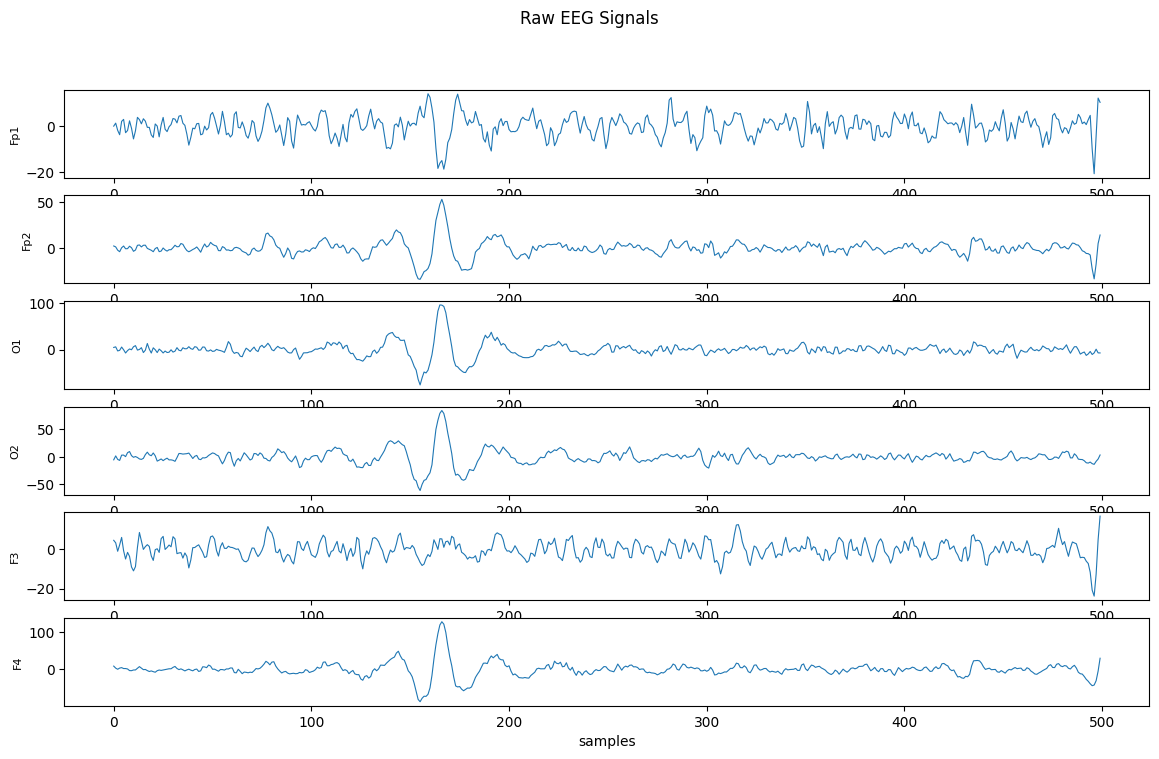

In [13]:
plt.figure(figsize=(14, 8))

for i in range(6):
    plt.subplot(6, 1, i+1)
    plt.plot(df.iloc[:500, i], linewidth=0.8)
    plt.ylabel(df.columns[i], fontsize=8)

plt.suptitle("Raw EEG Signals")
plt.xlabel("samples")
plt.show()

In [14]:
df_diff = pd.DataFrame()
df_diff['Fp1_Fp2'] = df['Fp1'] - df['Fp2']
df_diff['O1_O2']   = df['O1']  - df['O2']
df_diff['F3_F4']   = df['F3']  - df['F4']

In [15]:
print("shape:", df_diff.shape)
print("differential columns:", list(df_diff.columns))
df_diff.head()

shape: (8064, 3)
differential columns: ['Fp1_Fp2', 'O1_O2', 'F3_F4']


,Fp1_Fp2,O1_O2,F3_F4
0,-2.274670,9.959307,-4.030605
1,0.027955,4.075845,0.073104
2,0.425403,1.765594,-1.196745
3,0.173504,4.828836,-1.108311
4,1.740723,2.220837,1.528263


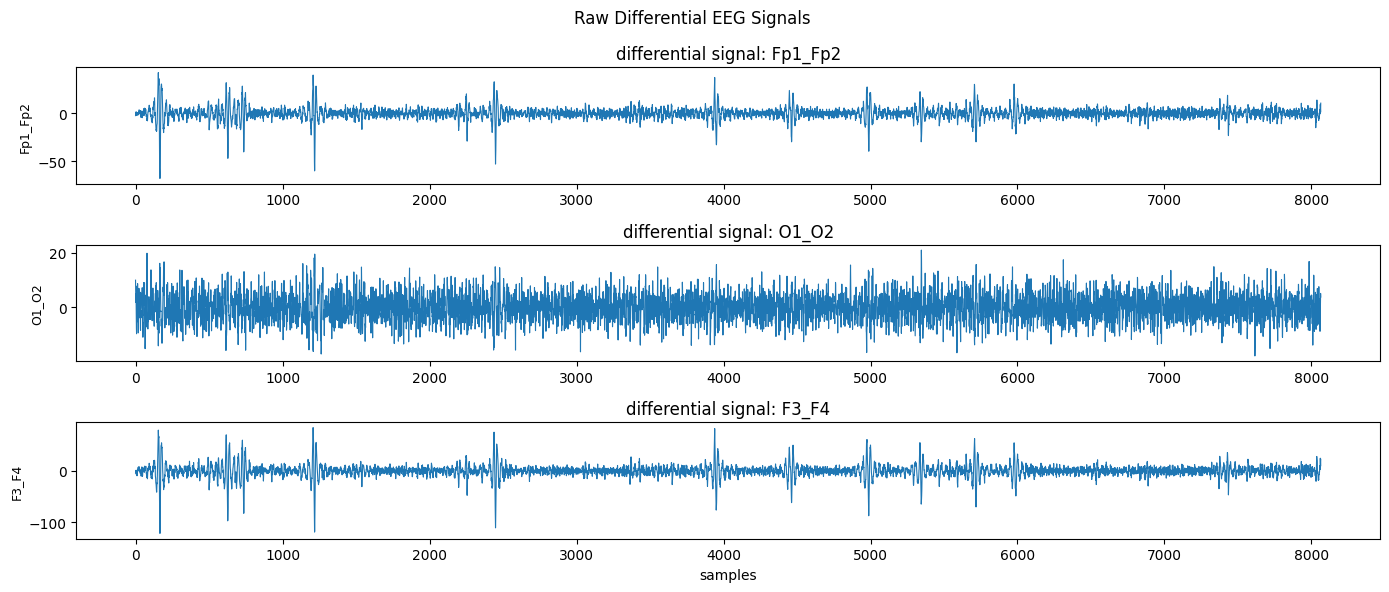

In [16]:
plt.figure(figsize=(14, 6))

channels = list(df_diff.columns)

for i in range(3):
    plt.subplot(3, 1, i+1)
    plt.plot(df_diff.iloc[:  , i], linewidth=0.8)
    plt.ylabel(channels[i], fontsize=9)
    plt.title("differential signal: " + channels[i])

plt.suptitle("Raw Differential EEG Signals ")
plt.xlabel("samples")
plt.tight_layout()
plt.show()

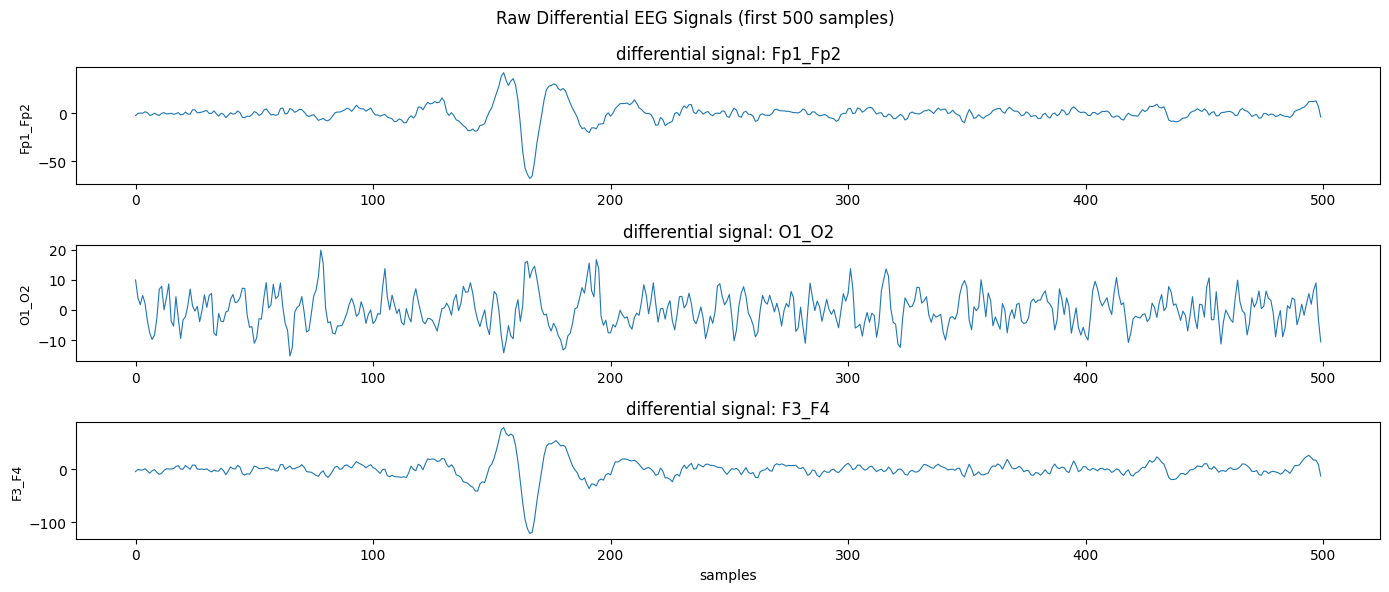

In [17]:
plt.figure(figsize=(14, 6))

channels = list(df_diff.columns)

for i in range(3):
    plt.subplot(3, 1, i+1)
    plt.plot(df_diff.iloc[:500, i], linewidth=0.8)
    plt.ylabel(channels[i], fontsize=9)
    plt.title("differential signal: " + channels[i])

plt.suptitle("Raw Differential EEG Signals (first 500 samples)")
plt.xlabel("samples")
plt.tight_layout()
plt.show()

In [18]:
def bandpass_filter(data):
    fs = 256
    lowcut = 0.5
    highcut = 50.0
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(4, [low, high], btype='band')
    filtered = filtfilt(b, a, data)
    return filtered

df_filtered = df_diff.copy()

for col in df_diff.columns:
    df_filtered[col] = bandpass_filter(df_diff[col].values)

print("bandpass filter applied to all 3 differential signals")

bandpass filter applied to all 3 differential signals


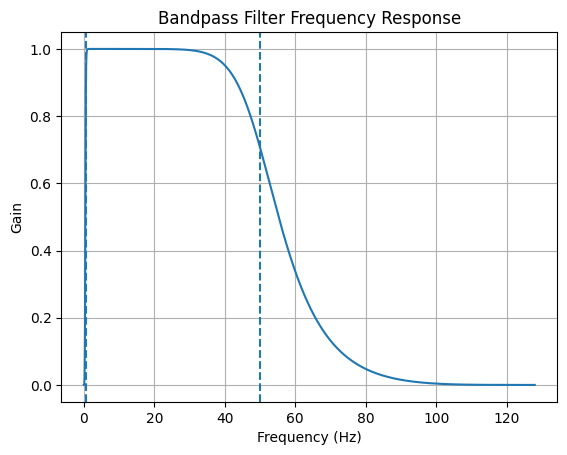

In [24]:
    fs = 256
    lowcut = 0.5
    highcut = 50.0
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(4, [low, high], btype='band')
    w, h = freqz(b, a, worN=8000)
    freq = (w / np.pi) * nyq
    
    for col in df_diff.columns:
        df_filtered[col] = bandpass_filter(df_diff[col].values)
plt.figure()
plt.plot(freq, abs(h))
plt.title("Bandpass Filter Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Gain")
plt.axvline(lowcut, linestyle='--')
plt.axvline(highcut, linestyle='--')
plt.grid()
plt.show()

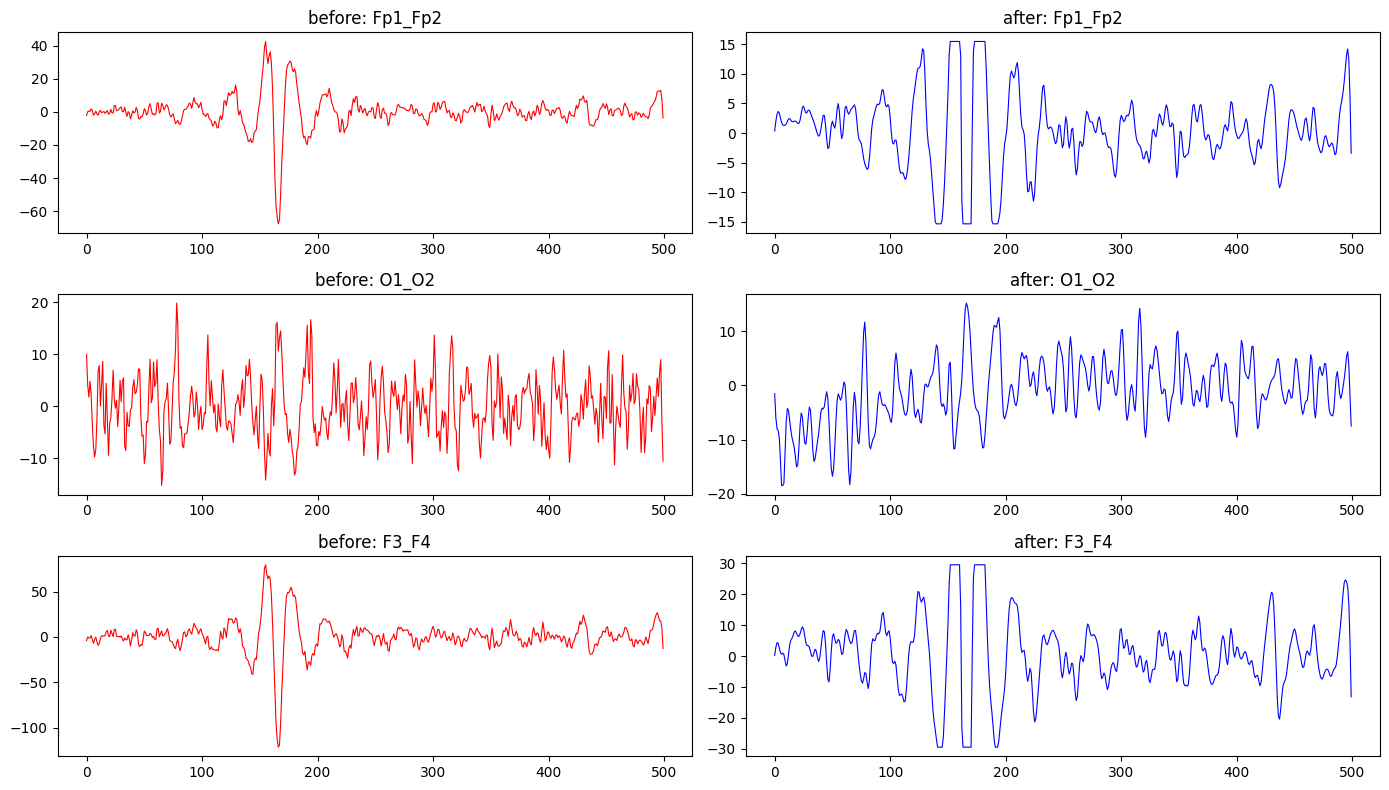

In [25]:
df_clean = df_filtered.copy()

for col in df_filtered.columns:
    q1 = df_filtered[col].quantile(0.25)
    q3 = df_filtered[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 3 * iqr
    upper = q3 + 3 * iqr
    df_clean[col] = df_filtered[col].clip(lower, upper)




fig, axes = plt.subplots(3, 2, figsize=(14, 8))
channels = list(df_diff.columns)

for i in range(3):
    axes[i][0].plot(df_diff[channels[i]][:500].values,
                    color='red', linewidth=0.8)
    axes[i][0].set_title("before: " + channels[i])

    axes[i][1].plot(df_clean[channels[i]][:500].values,
                    color='blue', linewidth=0.8)
    axes[i][1].set_title("after: " + channels[i])

plt.tight_layout()
plt.show()

In [100]:
window_size = 256
step_size = 128
fs = 256

def get_features(window):
    features = []
    names = []

    for col in window.columns:
        sig = window[col].values.astype(float)

        features += [
            np.mean(sig),
            np.std(sig),
            np.var(sig),
            stats.skew(sig),
            stats.kurtosis(sig),
            np.max(sig) - np.min(sig),
            np.sqrt(np.mean(sig**2)),
            np.sum(np.diff(np.sign(sig)) != 0) / len(sig)
        ]

        names += [
            col+'_mean', col+'_std', col+'_var',
            col+'_skew', col+'_kurt', col+'_ptp',
            col+'_rms', col+'_zcr'
        ]

    return features, names

print("ready - features per window:", 3 * 8)

ready - features per window: 24


In [101]:
all_features = []
feat_names = []

start = 0
while (start + window_size <= len(df_clean)):
    window = df_clean.iloc[start : start + window_size]
    feats, feat_names = get_features(window)
    all_features.append(feats)
    start += step_size

X = pd.DataFrame(all_features, columns=feat_names)
X = X.fillna(X.median())

print("windows:", X.shape[0])
print("features:", X.shape[1])
X.head()

windows: 62
features: 24


,Fp1_Fp2_mean,Fp1_Fp2_std,Fp1_Fp2_var,Fp1_Fp2_skew,Fp1_Fp2_kurt,Fp1_Fp2_ptp,Fp1_Fp2_rms,Fp1_Fp2_zcr,O1_O2_mean,O1_O2_std,...,O1_O2_rms,O1_O2_zcr,F3_F4_mean,F3_F4_std,F3_F4_var,F3_F4_skew,F3_F4_kurt,F3_F4_ptp,F3_F4_rms,F3_F4_zcr
0,0.735889,8.012410,64.198720,-0.220475,-0.165407,30.847323,8.046133,0.089844,-2.598804,6.719144,...,7.204213,0.113281,1.203481,14.502025,210.308717,-0.227834,0.071944,58.943368,14.551876,0.089844
1,-0.228831,7.772050,60.404754,0.058597,0.056891,30.847323,7.775418,0.113281,0.995558,5.223120,...,5.317153,0.167969,-0.416992,14.213599,202.026411,0.049464,0.214581,58.943368,14.219715,0.105469
2,-0.284178,4.166575,17.360346,-0.085716,1.726380,29.585707,4.176255,0.121094,0.450816,4.231860,...,4.255805,0.156250,-0.494982,8.317469,69.180294,-0.018231,1.795738,54.110740,8.332185,0.128906
3,0.240912,7.153976,51.179369,-0.020171,0.011358,30.847323,7.158031,0.097656,-0.279065,4.166673,...,4.176008,0.128906,0.336830,14.398566,207.318715,-0.053747,-0.140276,58.943368,14.402506,0.105469
4,0.353793,9.572932,91.641028,0.018110,-1.087957,30.847323,9.579467,0.074219,-0.131978,4.673444,...,4.675307,0.125000,0.363636,19.476309,379.326609,0.005173,-1.206533,58.943368,19.479703,0.074219


In [102]:
total_windows = len(X)
n_persons = max(2, min(20, total_windows // 40))

labels = []
for i in range(total_windows):
    person_num = (i * n_persons) // total_windows + 1
    labels.append("person_" + str(person_num))

y = np.array(labels)

In [103]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [104]:
x_train, x_test, y_train, y_test = train_test_split( X, y_encoded, test_size=0.2,random_state=42,stratify=y_encoded)

In [105]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [106]:
 x_train.shape

(49, 24)

In [107]:
 x_test.shape

(13, 24)

In [108]:

models = {
    'SVM': SVC(kernel='rbf', C=10,probability=True, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200,random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=7),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'MLP': MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=300, random_state=42)}

In [109]:
results = {}

for name in models:
    model = models[name]
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = {
        'model': model,
        'accuracy': acc,
        'y_pred': y_pred
    }
    print("  accuracy:", round(acc * 100, 2), "%")

  accuracy: 61.54 %
  accuracy: 69.23 %
  accuracy: 30.77 %
  accuracy: 61.54 %
  accuracy: 38.46 %
  accuracy: 61.54 %


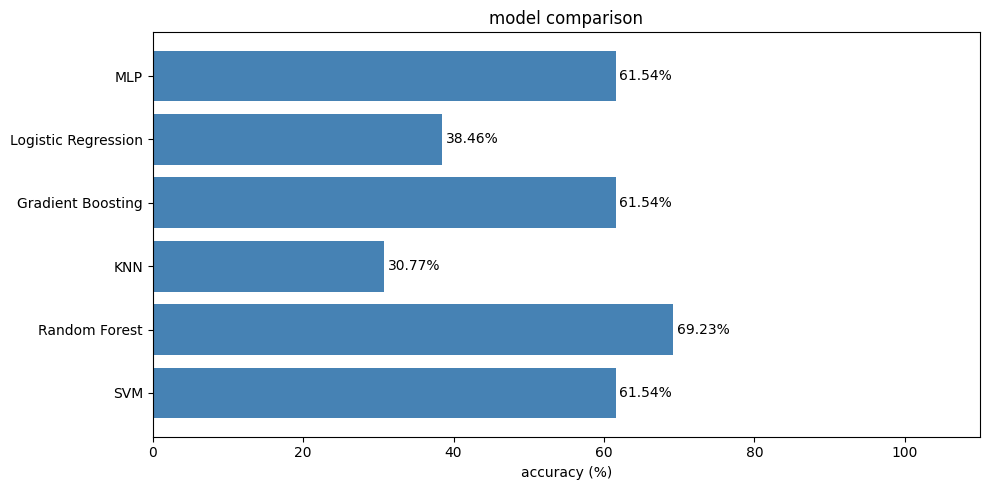

In [110]:
model_names = list(results.keys())
accuracies = [results[n]['accuracy'] * 100 for n in model_names]

plt.figure(figsize=(10, 5))
plt.barh(model_names, accuracies, color='steelblue')
plt.xlabel("accuracy (%)")
plt.title("model comparison")
plt.xlim(0, 110)

for i in range(len(model_names)):
    plt.text(accuracies[i] + 0.5, i,
             str(round(accuracies[i], 2)) + "%",
             va='center')

plt.tight_layout()
plt.show()

In [115]:
best_model = results['Random Forest']['model']
best_pred = results['Random Forest']['y_pred']
print(classification_report(y_test, best_pred, target_names=le.classes_))

              precision    recall  f1-score   support

    person_1       1.00      0.43      0.60         7
    person_2       0.60      1.00      0.75         6

    accuracy                           0.69        13
   macro avg       0.80      0.71      0.68        13
weighted avg       0.82      0.69      0.67        13



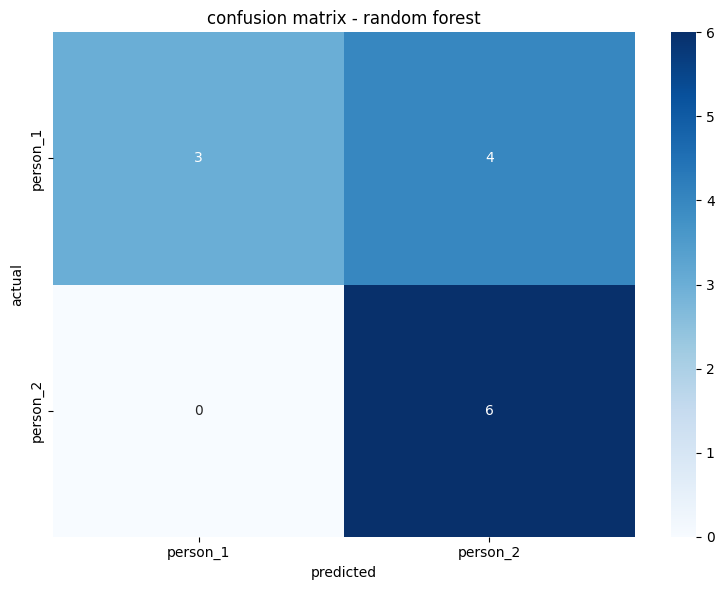

In [116]:
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.title("confusion matrix - random forest")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.tight_layout()
plt.show()

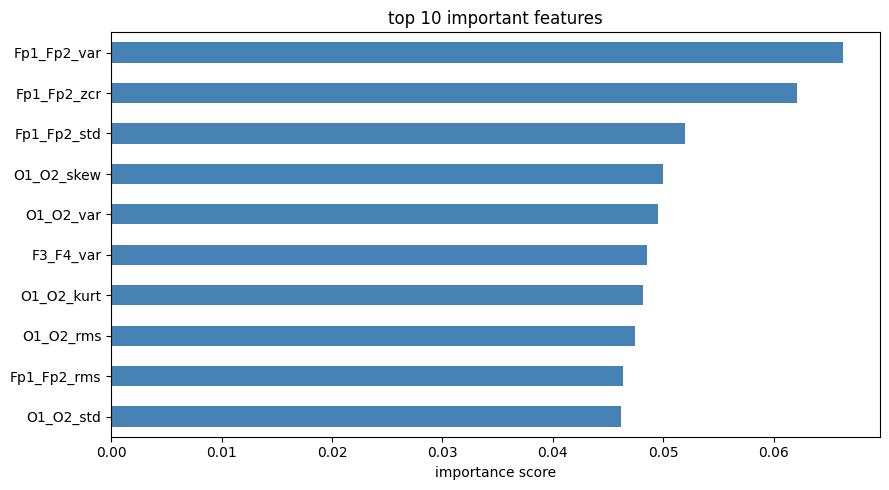

In [117]:
importance = best_model.feature_importances_
feat_series = pd.Series(importance, index=X.columns)
top10 = feat_series.sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
top10.sort_values().plot(kind='barh', color='steelblue')
plt.title("top 10 important features")
plt.xlabel("importance score")
plt.tight_layout()
plt.show()

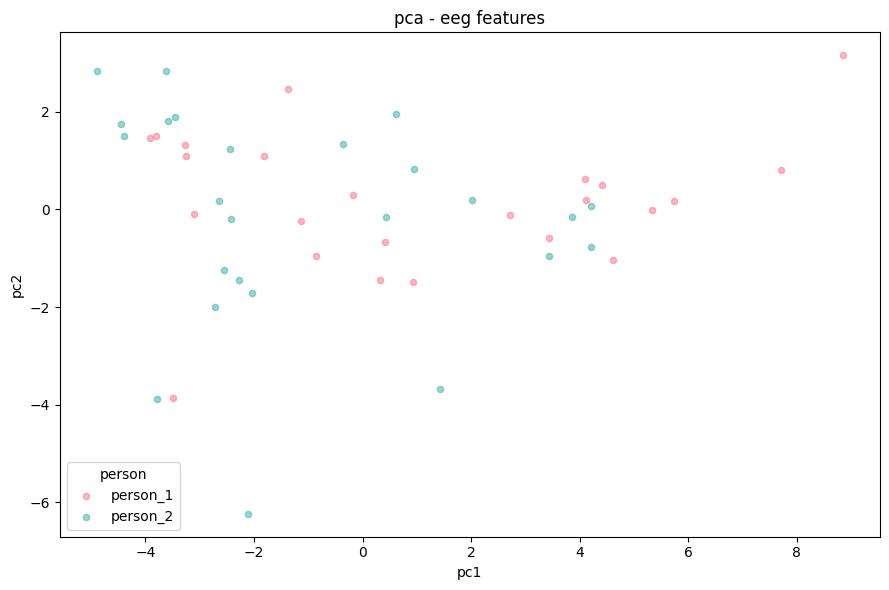

In [118]:
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_train)

colors = sns.color_palette('husl', n_persons)
plt.figure(figsize=(9, 6))

for i in range(n_persons):
    idx = y_train == i
    plt.scatter(x_pca[idx, 0], x_pca[idx, 1],
                label=le.classes_[i],
                alpha=0.5, s=20, color=colors[i])

plt.xlabel("pc1")
plt.ylabel("pc2")
plt.title("pca - eeg features")
plt.legend(title="person")
plt.tight_layout()
plt.show()

In [120]:

import joblib
joblib.dump(best_model, 'neuraverse_model.pkl')
joblib.dump(scaler, 'neuraverse_scaler.pkl')
joblib.dump(le, 'neuraverse_label_encoder.pkl')

print("saved successfully")
print("model: random forest")
print("accuracy:", round(results['Random Forest']['accuracy'] * 100, 2), "%")

saved successfully
model: random forest
accuracy: 69.23 %


In [127]:
def authenticate(window_df):
    diff = pd.DataFrame()
    diff['Fp1_Fp2'] = window_df['Fp1'] - window_df['Fp2']
    diff['O1_O2']   = window_df['O1']  - window_df['O2']
    diff['F3_F4']   = window_df['F3']  - window_df['F4']

    feats, _ = get_features(diff)
    vec = np.array(feats).reshape(1, -1)
    vec = np.nan_to_num(vec)

    # fix: convert to dataframe so feature names match
    vec_df = pd.DataFrame(vec, columns=X.columns)
    vec_sc = scaler.transform(vec_df)

    proba = best_model.predict_proba(vec_sc)[0]
    pred = np.argmax(proba)
    confidence = proba.max()
    person = le.inverse_transform([pred])[0]

    if confidence >= 0.6:
        status = "access granted"
    else:
        status = "access denied"

    return person, confidence, status

In [128]:
# simulating heart rate because hardware not connected yet
# when real hardware is ready, replace this with actual MAX30102 readings

np.random.seed(42)

def get_heart_rate():
    # normal range: 60-100 bpm
    # panic range: above 130 bpm
    hr = np.random.choice(
        [np.random.randint(60, 100),   # normal
         np.random.randint(130, 170)], # panic
        p=[0.7, 0.3]
    )
    return int(hr)

print("heart rate simulator ready")
print("sample readings:")
for i in range(5):
    print("  reading", i+1, ":", get_heart_rate(), "bpm")

heart rate simulator ready
sample readings:
  reading 1 : 98 bpm
  reading 2 : 67 bpm
  reading 3 : 78 bpm
  reading 4 : 83 bpm
  reading 5 : 62 bpm


In [129]:
def get_hr_zone(heart_rate):
    if heart_rate < 60:
        zone = "low"
    elif heart_rate <= 100:
        zone = "normal"
    elif heart_rate <= 130:
        zone = "elevated"
    else:
        zone = "panic"
    return zone

print("heart rate zones:")
print("  below 60  -> low")
print("  60 - 100  -> normal")
print("  101 - 130 -> elevated")
print("  above 130 -> panic")

heart rate zones:
  below 60  -> low
  60 - 100  -> normal
  101 - 130 -> elevated
  above 130 -> panic


In [132]:
EMERGENCY_CONTACTS = {
    "emergency contact": "9876543210",
    "medical info": "Blood Group: B+",
    "location sharing": "Live location sent to emergency contact"
}

def smart_authenticate(window_df, heart_rate, eeg_threshold=0.6, panic_threshold=130):

    # step 1 - get eeg result
    diff = pd.DataFrame()
    diff['Fp1_Fp2'] = window_df['Fp1'] - window_df['Fp2']
    diff['O1_O2']   = window_df['O1']  - window_df['O2']
    diff['F3_F4']   = window_df['F3']  - window_df['F4']

    feats, _ = get_features(diff)
    vec = np.array(feats).reshape(1, -1)
    vec = np.nan_to_num(vec)
    vec_df = pd.DataFrame(vec, columns=X.columns)
    vec = scaler.transform(vec_df)

    proba = best_model.predict_proba(vec)[0]
    pred = np.argmax(proba)
    confidence = proba.max()
    person = le.inverse_transform([pred])[0]

    # step 2 - get heart rate zone
    hr_zone = get_hr_zone(heart_rate)

    # step 3 - decision logic
    print("=" * 45)
    print("  neuraverse smart authentication")
    print("=" * 45)
    print("  person detected :", person)
    print("  eeg confidence  :", round(confidence * 100, 1), "%")
    print("  heart rate      :", heart_rate, "bpm")
    print("  hr zone         :", hr_zone)
    print("-" * 45)

    # case 1 - normal authentication
    if confidence >= eeg_threshold and hr_zone in ["normal", "low"]:
        print("  status : access granted")
        print("  mode   : normal")

    # case 2 - emergency mode
    # eeg matches strongly but heart rate is panic level
    elif confidence >= 0.75 and heart_rate >= panic_threshold:
        print("  status : emergency mode activated")
        print("  mode   : limited access only")
        print()
        print("  accessible features:")
        for key in EMERGENCY_CONTACTS:
            print("    ->", key, ":", EMERGENCY_CONTACTS[key])

    # case 3 - elevated stress but eeg matches
    # give access but flag it
    elif confidence >= eeg_threshold and hr_zone == "elevated":
        print("  status : access granted with warning")
        print("  mode   : stress detected, monitoring active")

    # case 4 - low confidence
    else:
        print("  status : access denied")
        print("  reason : eeg confidence too low")

    print("=" * 45)

In [133]:
original_6ch = pd.read_csv('features_raw.csv')
original_6ch.columns = original_6ch.columns.str.strip()
original_6ch = original_6ch[['Fp1', 'Fp2', 'O1', 'O2', 'F3', 'F4']]

print("running 4 test scenarios\n")

# test 1 - normal user, normal heart rate
print("scenario 1 - normal user, normal heart rate")
rand = np.random.randint(0, len(original_6ch) - window_size)
window = original_6ch.iloc[rand : rand + window_size]
smart_authenticate(window, heart_rate=72)

print()

# test 2 - normal user, panic heart rate (emergency)
print("scenario 2 - normal user, panic heart rate")
smart_authenticate(window, heart_rate=155)

print()

# test 3 - normal user, elevated heart rate
print("scenario 3 - normal user, elevated stress")
smart_authenticate(window, heart_rate=115)

print()

# test 4 - random window, low confidence expected
print("scenario 4 - low confidence case")
rand2 = np.random.randint(0, len(original_6ch) - window_size)
window2 = original_6ch.iloc[rand2 : rand2 + window_size]
smart_authenticate(window2, heart_rate=88)

running 4 test scenarios

scenario 1 - normal user, normal heart rate
  neuraverse smart authentication
  person detected : person_2
  eeg confidence  : 59.0 %
  heart rate      : 72 bpm
  hr zone         : normal
---------------------------------------------
  status : access denied
  reason : eeg confidence too low

scenario 2 - normal user, panic heart rate
  neuraverse smart authentication
  person detected : person_2
  eeg confidence  : 59.0 %
  heart rate      : 155 bpm
  hr zone         : panic
---------------------------------------------
  status : access denied
  reason : eeg confidence too low

scenario 3 - normal user, elevated stress
  neuraverse smart authentication
  person detected : person_2
  eeg confidence  : 59.0 %
  heart rate      : 115 bpm
  hr zone         : elevated
---------------------------------------------
  status : access denied
  reason : eeg confidence too low

scenario 4 - low confidence case
  neuraverse smart authentication
  person detected : perso